# EN3150 Assignment 03: Model A vs Model B comparison (Task 4)

Builds the Task 4 comparison from the files saved by `Model_A/src/ModelA.ipynb` and `Model_B/src/ModelB.ipynb`.
Nothing is trained here. Both models were trained with the same pipeline (splits, augmentation, Adam, 30 epochs,
batch 32) on the same GPU, so the differences come from replacing standard convolutions with depthwise
separable convolutions.

Outputs:
- `results/tables/model_a_vs_model_b.csv`
- `results/figures/model_a_vs_model_b_loss.png`

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root():
    current = Path.cwd().resolve()

    while current != current.parent:
        if (current / ".git").exists():
            return current

        current = current.parent

    raise FileNotFoundError("Could not find project root.")


PROJECT_ROOT = find_project_root()

METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Common.models import ModelA, ModelB
from Common.complexity import count_macs

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Comparison table

MACs (multiply-accumulate operations per $64 	imes 64$ image) are counted from the architectures with
`Common/complexity.py`; they match the hand calculation in the model notebooks.

In [2]:
metrics = pd.concat(
    [
        pd.read_csv(METRICS_DIR / "model_a_metrics.csv"),
        pd.read_csv(METRICS_DIR / "model_b_metrics.csv")
    ],
    ignore_index=True
).set_index("Model")

macs = {"Model A": count_macs(ModelA()), "Model B": count_macs(ModelB())}
assert macs == {"Model A": 9459200, "Model B": 1420800}

comparison = pd.DataFrame({
    "Trainable Parameters": metrics["Parameters"],
    "MACs per Image": pd.Series(macs),
    "Model Size on Disk (KB)": metrics["Actual Model Size (KB)"],
    "Estimated FP32 Size (KB)": metrics["Estimated FP32 Size (KB)"],
    "Training Time per Epoch (s)": metrics["Average Epoch Time (s)"],
    "Inference Time (ms/image)": metrics["Inference Time (ms/image)"],
    "Test Accuracy (%)": metrics["Test Accuracy"] * 100,
    "Macro Precision (%)": metrics["Macro Precision"] * 100,
    "Macro Recall (%)": metrics["Macro Recall"] * 100
})

comparison.to_csv(TABLES_DIR / "model_a_vs_model_b.csv")

comparison.round(2)

,Trainable Parameters,MACs per Image,Model Size on Disk (KB),Estimated FP32 Size (KB),Training Time per Epoch (s),Inference Time (ms/image),Test Accuracy (%),Macro Precision (%),Macro Recall (%)
Model A,45643,9459200,182.85,178.29,55.16,0.36,99.30,99.03,99.39
Model B,25526,1420800,105.74,99.71,47.85,0.34,97.72,98.08,98.21


Relative change when moving from Model A to Model B (negative = smaller / faster / lower). Accuracy, precision
and recall are shown as a difference in percentage points.

In [3]:
model_a, model_b = comparison.loc["Model A"], comparison.loc["Model B"]

relative_columns = [
    "Trainable Parameters",
    "MACs per Image",
    "Model Size on Disk (KB)",
    "Training Time per Epoch (s)",
    "Inference Time (ms/image)"
]
point_columns = ["Test Accuracy (%)", "Macro Precision (%)", "Macro Recall (%)"]

change = pd.Series(
    {column: f"{(model_b[column] / model_a[column] - 1) * 100:+.1f}%" for column in relative_columns}
    | {column: f"{model_b[column] - model_a[column]:+.2f} pts" for column in point_columns},
    name="Model B vs Model A"
)

change.to_frame()

,Model B vs Model A
Trainable Parameters,-44.1%
MACs per Image,-85.0%
Model Size on Disk (KB),-42.2%
Training Time per Epoch (s),-13.3%
Inference Time (ms/image),-4.9%
Test Accuracy (%),-1.58 pts
Macro Precision (%),-0.95 pts
Macro Recall (%),-1.18 pts


## 2. Training and validation loss

Both models over the same 30 epochs. Both histories record the loss of every epoch; the weights used for testing
are the ones from the epoch with the lowest validation loss.

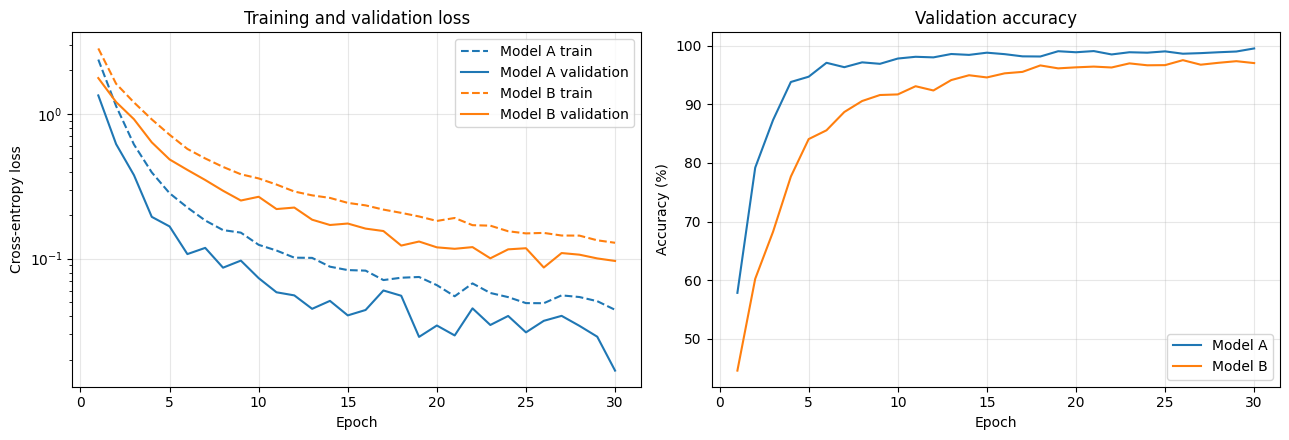

Model A: best validation loss 0.0168 at epoch 30, first epoch with validation accuracy >= 95%: 6
Model B: best validation loss 0.0868 at epoch 26, first epoch with validation accuracy >= 95%: 16


In [4]:
histories = {}
for name, file_name in [("Model A", "model_a_history.json"), ("Model B", "model_b_history.json")]:
    with (METRICS_DIR / file_name).open(encoding="utf-8") as history_file:
        histories[name] = json.load(history_file)

colors = {"Model A": "tab:blue", "Model B": "tab:orange"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, history in histories.items():
    epochs = range(1, len(history["train_loss"]) + 1)
    axes[0].plot(epochs, history["train_loss"], "--", color=colors[name], label=f"{name} train")
    axes[0].plot(epochs, history["val_loss"], "-", color=colors[name], label=f"{name} validation")
    axes[1].plot(epochs, np.array(history["val_accuracy"]) * 100, "-", color=colors[name], label=name)

axes[0].set_title("Training and validation loss")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_yscale("log")
axes[1].set_title("Validation accuracy")
axes[1].set_ylabel("Accuracy (%)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_a_vs_model_b_loss.png", dpi=300, bbox_inches="tight")
plt.show()

for name, history in histories.items():
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    first_95 = next((i + 1 for i, acc in enumerate(history["val_accuracy"]) if acc >= 0.95), None)
    print(
        f"{name}: best validation loss {min(history['val_loss']):.4f} at epoch {best_epoch}, "
        f"first epoch with validation accuracy >= 95%: {first_95}"
    )

## 3. Where Model B loses accuracy

Per-class recall from the two classification reports. The classes with the largest drop show which traffic signs
are hurt most by the lighter feature extractor.

In [5]:
reports = {}
for name, file_name in [
    ("Model A", "model_a_classification_report.json"),
    ("Model B", "model_b_classification_report.json")
]:
    with (METRICS_DIR / file_name).open(encoding="utf-8") as report_file:
        report = json.load(report_file)
    reports[name] = pd.DataFrame({k: v for k, v in report.items() if k.isdigit()}).T

recall = pd.DataFrame({
    "Support": reports["Model A"]["support"].astype(int),
    "Model A Recall (%)": reports["Model A"]["recall"] * 100,
    "Model B Recall (%)": reports["Model B"]["recall"] * 100
})
recall.index = recall.index.astype(int)
recall.index.name = "Class"
recall["Difference (pts)"] = recall["Model B Recall (%)"] - recall["Model A Recall (%)"]

print("Classes where Model B recall is lower:", int((recall["Difference (pts)"] < 0).sum()), "of 43")
recall.sort_values("Difference (pts)").head(8).round(2)

Classes where Model B recall is lower: 18 of 43


,Support,Model A Recall (%),Model B Recall (%),Difference (pts)
Class,,,,
2,233,100.00,91.85,-8.15
7,155,99.35,93.55,-5.81
0,19,100.00,94.74,-5.26
31,78,100.00,94.87,-5.13
8,144,99.31,94.44,-4.86
3,148,99.32,94.59,-4.73
5,209,98.09,93.78,-4.31
19,25,100.00,96.00,-4.00
